# [1] 04 Creep-event detection, size, extent and the slip budget

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps and the per-crossing fits take a few minutes.
```

**What this notebook does.** This is the only place event dates are defined:
every later notebook reads `creep_events.csv` from here.

1. **Detect** the events on the stacked fault-parallel series of the Tule Pond
   section (crossings within 2 km of the section centre): remove rate + annual
   cycle, run a matched filter for a step (mean of the next 3 epochs minus the
   previous 3), flag where it exceeds 3 robust sigma. Oakland (COZ1) is run the
   same way as the positive control: its creepmeter records the same events.
2. **Size and timing** from ONE joint model per stack (linear + annual + a step
   per event), grid-searching each onset over the acquisition epochs. The onset
   window is one acquisition interval. Amplitude CIs are block bootstraps.
3. **Along strike**: the same joint model at every crossing with the onsets
   held fixed gives per-event slip profiles, the inter-event (secular) rate
   and the event-driven fraction of slip.
4. **Section lengths**: (a) the length of fault hosting the events, where the
   cumulative event slip departs from zero (threshold from the flank scatter);
   (b) the width of the peak slip zone at 75% and 90% of the peak fraction.
5. **Band stack**: the joint model on the mean of the peak-zone crossings, the
   numbers the paper quotes for the five events.
6. **Slip budget**: secular + event-driven rate against the alignment arrays
   (refit over the InSAR window, and their whole-record rates) and creepmeters.
7. Recurrence intervals; Bo Xie's relocated seismicity and the repeating
   earthquakes near the section.

Ported from `Hayward_DISP-S1/analysis/run12_detect_events.py`,
`run14_event_fraction.py`, `hayward_creep/plotting/plot_event_summary.py` and
`plot_slip_budget.py`. One stream everywhere: 30 to 150 m, coherence 0.7.

**Outputs** (`outputs/04_event_detection/`): `creep_events.csv`,
`creepmeter_events_COZ1.csv`, `event_fraction_by_crossing.csv`,
`section_lengths.csv`, `band_stack_<band>.csv`, `slip_budget_by_crossing.csv`,
`aa_rates.csv`, `fig1_panels.npz`, `04_events_stats.txt`, registry rows `04_*`.

**Figures**: detection QC (supplement), Fig 1 (rotated map, hovmoller,
per-event profiles, rate budget, band stack), the slip budget along the fault.

**What to check.** Five Tule Pond events, two years apart, each about 10 mm on
the band stack; the two large COZ1 events also seen by its creepmeter; a
fraction of ~80% event-driven inside the section and ~10% outside; the budget
closing (secular + event-driven ~ the long-term array rate of ~6.5 mm/yr). The
CHECK cell compares every product with the previous run of this notebook.

In [1]:
# [2]
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, segments, creepmeters, params, coh_timeseries,
                                dist_min, dist_max, rate_smooth_km, paths_out, repo_dir)

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # the FP velocity map from 02
import pyproj                                    # lon/lat <-> UTM
import xarray as xr                              # grids for pygmt
from scipy.ndimage import gaussian_filter1d      # along-fault smoothing
import matplotlib.pyplot as plt
import pygmt

## [3] Paths and parameters

In [2]:
# [4]
notebook = "04_event_detection"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version of this notebook, for the CHECK cell

# the detector
stack_half_km = 2.0     # half-width of the peak-slip stack about the section centre; a whole-section
#                         average dilutes the transient with non-slipping fault
win_n = 3               # epochs each side in the matched filter (3 x ~6 d: sharp against months-long wander)
k_sigma = 3.0           # detection threshold in robust sigma of the statistic
merge_yr = 0.15         # flags closer than this are one event
onset_search_yr = 0.10  # grid-search the onset over acquisition epochs within this of the detection
nboot, block_years, seed = 2000, 1.0, 0    # block bootstrap for the amplitude CIs

# along strike
min_epoch_frac = 0.5    # a crossing needs >50% finite epochs to be fitted
smooth_km = 0.4         # along-fault smoothing of the profiles (gap-preserving)
total_floor_mm = 1.0    # |total slip| below this: fraction undefined
band_fracs = (0.75, 0.90)   # the peak slip zone: fraction >= this x its local peak
band_main = 0.90            # the band the figures draw and the paper quotes
flank_km = ((52.0, 56.0), (64.0, 68.0))   # flanks used for the creep-length threshold (Tule Pond)
seis_max_dist_km = 2.0  # seismicity and repeaters within this of the trace
neg_floor_frac = 0.2    # hovmoller colour scale starts at -this x vmax so early-epoch noise is not clipped to white

# the slip budget and the alignment arrays
aa_min_surveys, aa_min_span_yr = 4, 5.0    # an array is refit over the InSAR window only with this many surveys / span
km_lim = (15.0, 70.0)
strike_map = 144.0      # page rotation of the map panel (mean strike, notebook 02)
map_half_km = 10.9      # map panel cross-fault half-width: 3.4 cm wide for 73 km tall at true scale
map_u_max = 70.0        # the map stops just south of CFW1 (km from Point Pinole)
ref_patch_km = 5.0      # map display reference: CTM1-COZ1 patch, +/- this across the fault

# the two sections: (title, segment key, fraction column, seed centre km, half-span km, creepmeter)
SEGS = [("Tule Pond", "TULEPOND", "tulepond", 58.0, 10.0, ""),
        ("Oakland (control)", "COZ1", "coz1", 32.0, 15.0, "COZ1")]

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, map_file, common_paths["fault_profiles"], common_paths["aa_summary"],
           common_paths["CRE_Taira"], common_paths["CRE_Wald"], common_paths["growclust_cat"],
           utils.creepmeter_file(common_paths["creepmeter_dir"], "COZ1"))

Registry for 04_event_detection: run 0c591768, git dc940a6+


## [5] Load: the fault-parallel time series, the along-fault axis, the trace

In [3]:
# [6]
# the fault-parallel time series from 03: lat x decimal year, mm, rows south -> north
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_ts = fp_ts.sort_index()
lats = fp_ts.index.values
dates = fp_ts.columns.values.astype(float)
fp_matrix = fp_ts.values
t0, t1 = float(dates.min()), float(dates.max())
span = t1 - t0

# the along-fault axis: km from Point Pinole, increasing south
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])
km = to_km(lats)
north_to_south = np.argsort(km)
km_sorted, lats_sorted = km[north_to_south], lats[north_to_south]


def lat_of_km(km_value):
    return float(np.interp(km_value, km_sorted, lats_sorted))


x_fault = pd.read_csv(common_paths["fault_profiles"])
print(f"fp_ts: {len(lats)} crossings ({km.min():.1f} to {km.max():.1f} km from Point Pinole) x {len(dates)} epochs, "
      f"{t0:.3f} to {t1:.3f} ({span:.2f} yr); coherence {coh_timeseries}")


def daily_creepmeter(code):
    """Daily creepmeter record over the InSAR window, gross outliers removed, zeroed at the first day."""
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    slip = cm["slip_mm"].values
    median = np.median(slip)
    mad = np.median(np.abs(slip - median)) or 1.0
    cm = cm[np.abs(slip - median) < 6 * 1.4826 * mad + 10].reset_index(drop=True)
    return cm["decimal_year"].values, cm["slip_mm"].values - cm["slip_mm"].values[0]


def load_stack(seg):
    """Mean of the fp_ts rows within +/- stack_half_km of the section centre (rows with >50% valid epochs).
    Returns (dates, stack_mm, n_crossings) at the epochs where the mean is finite."""
    half_width_deg = stack_half_km / 111.19           # fp_ts is indexed by latitude: 1 km = 1/111.19 deg
    nearby = fp_ts[(fp_ts.index >= seg["lat"] - half_width_deg) & (fp_ts.index <= seg["lat"] + half_width_deg)]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(stack)
    return dates[ok], stack[ok], len(nearby)

fp_ts: 610 crossings (0.0 to 68.3 km from Point Pinole) x 439 epochs, 2016.672 to 2026.216 (9.54 yr); coherence 0.7


## [7] The detector and the joint model

A creep event is a STEP in the residual after rate + annual cycle. The
residual wanders by +/-2 mm over months (residual atmosphere), comparable to
the step sizes, so the detector keys on sharpness (a short-window difference)
and not on the level. It is one-sided: only forward steps (the fault does not
slip backwards). Timing comes from the detector, amplitude from the joint
fit, because a fit made locally around one event absorbs part of it into its
own trend. Every function here is used on both stacks, on the creepmeter and
again along strike.

**The joint model** is always the whole thing at once: constant + rate +
annual sine and cosine + one Heaviside step per event. `rss` is its residual
sum of squares, sum over epochs of (data - model)^2 in mm^2; rss / n epochs
is the rms the printouts quote.

**Timing, then amplitude.** `grid_search` finds the timing of ONE event: it
moves that event's step over the acquisition epochs within +/- 0.10 yr of the
detector's flag, refits the joint model with the other events held fixed, and
keeps the epoch with the lowest rss; the epochs whose rss is within one
variance unit of the best give the onset window. `fit_all_events` runs that
search for each event in turn, twice through so every onset settles against
the others, then makes one final joint fit with the onsets fixed: the step
coefficients of that fit are the amplitudes, and the block bootstrap on the
same fit gives their 95% intervals.

**Why every event is a step.** At 6 to 12 day sampling and this noise level
the onset and the end of an event are not separately resolved. A
finite-duration ramp was tested and rejected: the model-selection test that
seemed to favour a duration assumes independent residuals, and ours are not
(the residual atmosphere wanders over months, exactly the shape a ramp
absorbs). The test is kept in `hayward_creep/analysis/event_duration_bic.py`
for a reviewer; assumptions register row 16. The same correlated residuals
are why the amplitude CIs are a block bootstrap and not OLS standard errors,
which would understate them 2 to 3 times.

In [4]:
# [8]
def detrend_rate_annual(dates, values):
    """Remove constant + rate + annual cycle. Returns (residual, coefficients)."""
    A = np.c_[np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    coef, *_ = np.linalg.lstsq(A, values, rcond=None)
    return values - np.dot(A, coef), coef                 # np.dot(A, coef) = the model at every epoch


def step_statistic(dates, residual, n=win_n):
    """Mean of the next n epochs minus the mean of the previous n, at each gap.
    Returns (gap midpoints, statistic)."""
    stat_dates = 0.5 * (dates[n:len(dates) - n] + dates[n - 1:len(dates) - n - 1])
    stat_values = np.array([residual[i:i + n].mean() - residual[i - n:i].mean() for i in range(n, len(dates) - n)])
    return stat_dates, stat_values


def detect(dates, residual, n=win_n, k=k_sigma):
    """Forward steps above k robust sigma of the statistic; flags within merge_yr are one event
    (the larger kept). Returns ([(onset, statistic), ...], sigma, stat_dates, stat_values)."""
    stat_dates, stat_values = step_statistic(dates, residual, n)
    stat_sigma = utils.robust_sigma(stat_values)
    detections = []
    for i in np.where(stat_values > k * stat_sigma)[0]:
        if detections and stat_dates[i] - detections[-1][0] < merge_yr:
            if stat_values[i] > detections[-1][1]:
                detections[-1] = (stat_dates[i], stat_values[i])
        else:
            detections.append((stat_dates[i], stat_values[i]))
    return detections, stat_sigma, stat_dates, stat_values


def design(dates, onsets):
    """Columns: constant, rate, annual sin and cos, then one step per onset."""
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    columns += [(dates > onset).astype(float) for onset in onsets]
    return np.column_stack(columns)


def fit_joint(dates, values, onsets):
    """Least-squares fit of the joint model (constant + rate + annual + a Heaviside step at each onset).
    Returns (coefficients, rss), rss = sum over epochs of (data - model)^2 in mm^2."""
    G = design(dates, onsets)
    coef, *_ = np.linalg.lstsq(G, values, rcond=None)
    return coef, float(np.sum((values - np.dot(G, coef)) ** 2))


def grid_search(dates, values, onsets, i):
    """TIMING of event i, the other onsets held fixed: try every acquisition epoch within
    +/- onset_search_yr of the detector's flag as the step's onset, refit the whole joint model
    each time, keep the epoch with the lowest rss. Returns (best onset, (lo, hi)) where lo-hi
    spans the candidate epochs whose rss is within one variance unit (rss / dof) of the best."""
    onset_0 = onsets[i]
    candidates = dates[(dates > onset_0 - onset_search_yr) & (dates < onset_0 + onset_search_yr)]
    if len(candidates) == 0:
        candidates = np.array([onset_0])
    trial = list(onsets)
    rss_at = {}
    for candidate in candidates:
        trial[i] = candidate
        _, rss_at[candidate] = fit_joint(dates, values, trial)
    best = min(rss_at, key=rss_at.get)
    variance = rss_at[best] / max(len(dates) - (4 + len(onsets)), 1)
    within = [candidate for candidate, rss in rss_at.items() if rss - rss_at[best] <= variance]
    return best, (min(within), max(within))


def bootstrap_amplitudes(dates, values, onsets):
    """Moving-block bootstrap 95% CI on each step (onsets fixed). Returns (ci_lo, ci_hi) per event."""
    rng = np.random.default_rng(seed)
    G = design(dates, onsets)
    pinv = np.linalg.pinv(G)
    fitted = np.dot(G, np.dot(pinv, values))
    residual = values - fitted
    n = len(dates)
    block = int(max(2, min(round(block_years / np.median(np.diff(dates))), n)))
    n_blocks = int(np.ceil(n / block))
    draws = np.empty((nboot, len(onsets)))
    for k in range(nboot):
        starts = rng.integers(0, n - block + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        draws[k] = np.dot(pinv, fitted + residual[idx])[4:]
    return np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


def fit_all_events(dates, values, onsets, npass=2):
    """Timing then amplitude. Grid-search each onset in turn holding the others, twice through;
    then ONE joint fit with the onsets fixed gives the amplitudes (the step coefficients), and
    the block bootstrap on that fit gives their 95% CIs. Returns ([one dict per event], coefficients, rss)."""
    onsets = list(onsets)
    bounds = [(onset, onset) for onset in onsets]
    for _ in range(npass):
        for i in range(len(onsets)):
            onsets[i], bounds[i] = grid_search(dates, values, onsets, i)
    coef, rss = fit_joint(dates, values, onsets)
    amp_lo, amp_hi = bootstrap_amplitudes(dates, values, onsets)
    fits = []
    for i, onset in enumerate(onsets):
        before = dates[dates < bounds[i][0]]          # the event happened in the interval before the epoch
        onset_lo = float(before.max()) if len(before) else float(bounds[i][0])
        fits.append(dict(onset_yr=float(onset), onset_lo=onset_lo, onset_hi=float(max(bounds[i][1], onset)),
                         amplitude_mm=float(coef[4 + i]), amp_lo=float(amp_lo[i]), amp_hi=float(amp_hi[i])))
    return fits, coef, rss

## [9] RUN: detect and fit on the two stacks

Everything the QC figure and the registry need for each section is kept in
`solutions[key]`.

In [5]:
# [10]
event_rows = []
solutions = {}
for title, key, col, centre, half_span, cmcode in SEGS:
    seg = segments[key]
    stack_dates, stack, n_crossings = load_stack(seg)
    residual, coef = detrend_rate_annual(stack_dates, stack)
    detections, stat_sigma, stat_dates, stat_values = detect(stack_dates, residual)
    print(f"=== {title}: stack of {n_crossings} crossings, {len(stack_dates)} epochs, statistic sigma {stat_sigma:.3f} mm, "
          f"threshold {k_sigma * stat_sigma:.2f} mm")
    fits, coef_events, rss = fit_all_events(stack_dates, stack, [onset for onset, stat in detections])
    print(f"    joint model: rate {coef_events[1]:.2f} mm/yr, annual {np.hypot(coef_events[2], coef_events[3]):.2f} mm, "
          f"rms {np.sqrt(rss / len(stack_dates)):.2f} mm")

    # the control: the same joint model and the same detector (window matched in TIME) on the creepmeter
    cm_amps, cm_detections, cm_series = [], [], None
    if cmcode:
        cm_dates, cm_slip = daily_creepmeter(cmcode)
        coef_cm, _ = fit_joint(cm_dates, cm_slip, [f["onset_yr"] for f in fits])
        cm_amps = [float(a) for a in coef_cm[4:]]
        cm_residual, _ = detrend_rate_annual(cm_dates, cm_slip)
        n_cm = max(2, int(round(win_n * np.median(np.diff(stack_dates)) / np.median(np.diff(cm_dates)))))
        cm_detections, cm_sigma, _, _ = detect(cm_dates, cm_residual, n_cm)
        cm_series = (cm_dates, cm_slip)
        insar_stat_at_cm = [float(stat_values[int(np.argmin(np.abs(stat_dates - onset)))] / stat_sigma) for onset, stat in cm_detections]
        pd.DataFrame([dict(creepmeter=cmcode, onset_yr=round(onset, 4), stat_mm=round(stat, 2), sigma_mm=round(cm_sigma, 3),
                           insar_stat_sigma=round(z, 2),
                           insar_detected=bool(any(abs(f["onset_yr"] - onset) < merge_yr for f in fits)))
                      for (onset, stat), z in zip(cm_detections, insar_stat_at_cm)]
                     ).to_csv(os.path.join(out_dir, f"creepmeter_events_{cmcode}.csv"), index=False)
        print(f"    {cmcode} creepmeter detected independently ({n_cm} d window, threshold {k_sigma * cm_sigma:.2f} mm): "
              f"{[round(onset, 3) for onset, stat in cm_detections]}; InSAR statistic at those onsets, in sigma: "
              f"{[round(z, 2) for z in insar_stat_at_cm]}")

    for i, ((onset, stat), f) in enumerate(zip(detections, fits)):
        window_days = (f["onset_hi"] - f["onset_lo"]) * 365.25
        cm_step = cm_amps[i] if cmcode else np.nan
        print(f"    {f['onset_yr']:.4f}  window [{f['onset_lo']:.4f}, {f['onset_hi']:.4f}] = {window_days:.0f} d   "
              f"amp {f['amplitude_mm']:.2f} [{f['amp_lo']:.2f}, {f['amp_hi']:.2f}] mm" + (f"   creepmeter {cm_step:+.2f} mm" if cmcode else ""))
        event_rows.append(dict(segment=key, label=seg["label"], onset_yr=round(f["onset_yr"], 4), onset_lo=round(f["onset_lo"], 4),
                               onset_hi=round(f["onset_hi"], 4), onset_window_days=round(window_days, 1), amplitude_mm=round(f["amplitude_mm"], 2),
                               amp_lo=round(f["amp_lo"], 2), amp_hi=round(f["amp_hi"], 2), detect_stat_mm=round(float(stat), 2),
                               detect_sigma_mm=round(stat_sigma, 3), stream=params, k_sigma=k_sigma, creepmeter=cmcode or "",
                               creepmeter_step_mm=(round(cm_step, 2) if cmcode else np.nan)))
    solutions[key] = dict(dates=stack_dates, stack=stack, n=n_crossings, fits=fits, coef=coef_events, rss=rss,
                          detections=detections, stat_sigma=stat_sigma, stat_dates=stat_dates, stat_values=stat_values,
                          cm_detections=cm_detections, cm_series=cm_series, cmcode=cmcode)
    print("")

creep_events = pd.DataFrame(event_rows)
creep_events.to_csv(os.path.join(out_dir, "creep_events.csv"), index=False)
print(f"{len(creep_events)} events saved to creep_events.csv")
tulepond_events = creep_events[creep_events.segment == "TULEPOND"].reset_index(drop=True)
onsets_tulepond = tulepond_events["onset_yr"].to_numpy(float)
assert len(tulepond_events) == 5, f"expected the five Tule Pond events, got {len(tulepond_events)}"

=== Tule Pond: stack of 45 crossings, 428 epochs, statistic sigma 0.763 mm, threshold 2.29 mm
    joint model: rate 2.06 mm/yr, annual 0.48 mm, rms 0.80 mm
    2017.0986  window [2017.0822, 2017.0986] = 6 d   amp 9.17 [8.12, 10.30] mm
    2019.1863  window [2019.1699, 2019.1863] = 6 d   amp 9.17 [8.28, 10.08] mm
    2021.1068  window [2021.0904, 2021.1068] = 6 d   amp 8.39 [7.59, 9.24] mm
    2023.0795  window [2023.0466, 2023.0795] = 12 d   amp 8.76 [7.91, 9.61] mm
    2024.9836  window [2024.9508, 2024.9836] = 12 d   amp 6.64 [5.87, 7.35] mm

=== Oakland (control): stack of 38 crossings, 428 epochs, statistic sigma 0.485 mm, threshold 1.46 mm
    joint model: rate 2.65 mm/yr, annual 0.28 mm, rms 0.88 mm


    COZ1 creepmeter detected independently (18 d window, threshold 0.55 mm): [np.float64(2019.053), np.float64(2021.779), np.float64(2022.141), np.float64(2022.725), np.float64(2023.067), np.float64(2024.422)]; InSAR statistic at those onsets, in sigma: [3.59, 2.06, 4.44, 0.78, -2.65, 2.26]
    2019.0219  window [2019.0055, 2019.0219] = 6 d   amp 2.30 [1.22, 3.45] mm   creepmeter +3.94 mm
    2022.1260  window [2022.0932, 2022.1260] = 12 d   amp 4.67 [3.46, 5.97] mm   creepmeter +7.31 mm

7 events saved to creep_events.csv


## [11] CHECK: the detection does not depend on the exact threshold

The paper says the five Tule Pond events are returned for every threshold
between 3 and 4 sigma. Re-run the detector at 3.0, 3.5 and 4.0.

In [6]:
# [12]
stack_dates, stack, n_crossings = load_stack(segments["TULEPOND"])
residual, _ = detrend_rate_annual(stack_dates, stack)
for k in (3.0, 3.5, 4.0):
    detections, _, _, _ = detect(stack_dates, residual, k=k)
    print(f"  K = {k:.1f} sigma: {len(detections)} events at {[round(onset, 2) for onset, stat in detections]}")

  K = 3.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 3.5 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 4.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]


## [13] Figure: detection QC

Top: the stacked series with the joint model and the detections (dashed) and,
for Oakland, the creepmeter (offset) with its own independent detections
(solid). Bottom: the step statistic against the threshold. A solid line with
no dashed partner is a creepmeter event the InSAR statistic leaves below
threshold: the detection limit, read straight off the figure.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-09-30/figS_event_detection_ap30-150m_coh0.7_mp5_sw200m_k3_win3.png


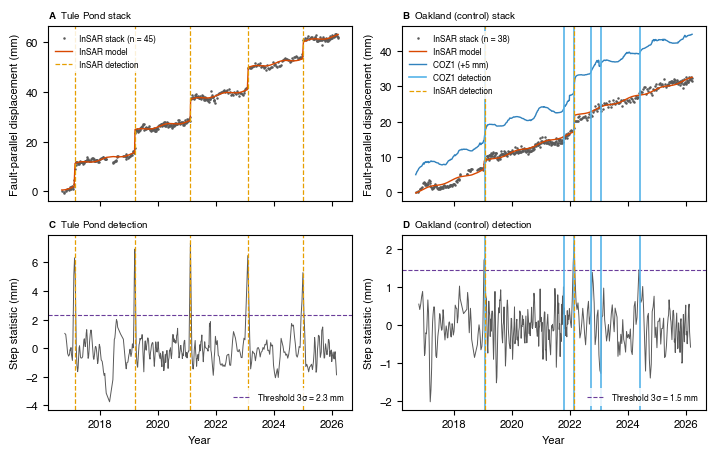

In [7]:
# [14]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6), sharex=True)
for j, (title, key, col, centre, half_span, cmcode) in enumerate(SEGS):
    sol = solutions[key]
    # top: the stack, the joint model, the detections
    ax = axes[0, j]
    ax.plot(sol["dates"], sol["stack"] - sol["stack"][0], ".", ms=1.6, color="0.35", label=f"InSAR stack (n = {sol['n']})")
    G = design(sol["dates"], [f["onset_yr"] for f in sol["fits"]])
    coef, *_ = np.linalg.lstsq(G, sol["stack"], rcond=None)
    ax.plot(sol["dates"], np.dot(G, coef) - sol["stack"][0], "-", lw=1.0, color="#D94801", label="InSAR model")
    if sol["cm_series"] is not None:
        cm_dates, cm_slip = sol["cm_series"]
        ax.plot(cm_dates, cm_slip - cm_slip[0] + 5.0, "-", lw=1.0, color="#3182BD", label=f"{cmcode} (+5 mm)")
    for i, (onset, stat) in enumerate(sol["cm_detections"]):
        ax.axvline(onset, color="#56B4E9", lw=1.2, label=f"{cmcode} detection" if i == 0 else None)
    for i, (onset, stat) in enumerate(sol["detections"]):
        ax.axvline(onset, color="#E69F00", lw=0.9, ls="--", label="InSAR detection" if i == 0 else None)
    ax.set_ylabel("Fault-parallel displacement (mm)")
    utils.panel_title(ax, "AB"[j], f"{title} stack")
    ax.legend(fontsize=6, loc="upper left")
    # bottom: the step statistic against the threshold
    ax = axes[1, j]
    ax.axhline(k_sigma * sol["stat_sigma"], color="#6A3D9A", lw=0.8, ls="--", label=f"Threshold {k_sigma:g}$\\sigma$ = {k_sigma * sol['stat_sigma']:.1f} mm")
    ax.plot(sol["stat_dates"], sol["stat_values"], "-", lw=0.7, color="0.35")
    for onset, stat in sol["cm_detections"]:
        ax.axvline(onset, color="#56B4E9", lw=1.2)
    for onset, stat in sol["detections"]:
        ax.axvline(onset, color="#E69F00", lw=0.9, ls="--")
    ax.set_ylabel("Step statistic (mm)")
    ax.set_xlabel("Year")
    utils.panel_title(ax, "CD"[j], f"{title} detection")
    ax.legend(fontsize=6, loc="lower right")
fig.tight_layout()
f_detect = os.path.join(fig_dir, f"figS_event_detection_{params}_k{k_sigma:g}_win{win_n}.png")
fig.savefig(f_detect, dpi=300)
fig.savefig(f_detect.replace(".png", ".pdf"))
print("Saved figure to:", f_detect)
plt.show()

## [15] Along strike: the joint model at every crossing

The same design (linear + annual + a step at each onset, held fixed) fitted
crossing by crossing. Away from its section an event's amplitude fits to
noise about zero, which is how the along-strike extent is read. The
event-driven fraction is the section's summed event slip over the total slip
in the window; it is a regression ratio and is not confined to 0 to 100%.

In [8]:
# [16]
def gaussian_smooth_km(x, lats_of_x, sigma_km):
    """NaN-aware, gap-preserving Gaussian smoothing along the fault."""
    spacing_km = float(np.median(np.abs(np.diff(lats_of_x)))) * 111.19
    sig = max(sigma_km / spacing_km, 0.5)
    finite = np.isfinite(x).astype(float)
    filled = np.where(finite > 0, x, 0.0)
    den = gaussian_filter1d(finite, sig, mode="nearest")
    out = np.divide(gaussian_filter1d(filled, sig, mode="nearest"), den, out=np.full_like(filled, np.nan), where=den > 0.15)
    out[~np.isfinite(x)] = np.nan
    return out


def interp_nan(x, y):
    """Bridge NaN gaps inside the data range by linear interpolation (x must be sorted)."""
    y = np.asarray(y, float).copy()
    ok = np.isfinite(y)
    if ok.sum() >= 2:
        inner = (x >= x[ok][0]) & (x <= x[ok][-1])
        fill = inner & ~ok
        y[fill] = np.interp(x[fill], x[ok], y[ok])
    return y


# the joint model with every onset of both sections, at every crossing
onsets_all = creep_events["onset_yr"].to_numpy(float)
segment_of = creep_events["segment"].to_numpy()
design_all = design(dates, onsets_all)
inter_event_rate = np.full(len(lats), np.nan)
event_amp = np.full((len(onsets_all), len(lats)), np.nan)         # one row per event, one column per crossing
for i in range(len(lats)):
    values = fp_matrix[i]
    ok = np.isfinite(values)
    if ok.sum() < min_epoch_frac * len(dates):
        continue
    coef_i, *_ = np.linalg.lstsq(design_all[ok], values[ok], rcond=None)
    inter_event_rate[i] = coef_i[1]
    event_amp[:, i] = coef_i[4:]

# per section: summed event slip, the event-driven fraction, and the numbers within 2 km of the centre
columns = {"lat": lats, "km": km, "inter_event_rate": inter_event_rate,
           "inter_event_rate_smooth": gaussian_smooth_km(inter_event_rate, lats, smooth_km)}
frac_stats = {}
for title, key, col, centre, half_span, cmcode in SEGS:
    in_segment = segment_of == key
    event_sum = event_amp[in_segment].sum(axis=0)
    total = inter_event_rate * span + event_sum
    fraction = 100 * event_sum / np.where(np.abs(total) > total_floor_mm, total, np.nan)
    columns[f"event_sum_{col}"] = event_sum
    columns[f"event_frac_{col}"] = fraction
    columns[f"event_frac_{col}_smooth"] = gaussian_smooth_km(fraction, lats, smooth_km)
    for j in np.flatnonzero(in_segment):
        columns[f"amp_{onsets_all[j]:.3f}"] = event_amp[j]
    half_width_deg = 2.0 / 111.19
    near_centre = (lats >= segments[key]["lat"] - half_width_deg) & (lats <= segments[key]["lat"] + half_width_deg)
    fraction_valid = fraction[near_centre & np.isfinite(fraction)]
    frac_stats[key] = dict(n=int(near_centre.sum()), sum_median=float(np.nanmedian(event_sum[near_centre])), median=float(np.median(fraction_valid)),
                           p5=float(np.percentile(fraction_valid, 5)), p95=float(np.percentile(fraction_valid, 95)))
    print(f"{title}: {near_centre.sum()} crossings within 2 km; summed event slip median {np.nanmedian(event_sum[near_centre]):.1f} mm; "
          f"fraction median {np.median(fraction_valid):.0f}%, 5-95% {np.percentile(fraction_valid, 5):.0f} to {np.percentile(fraction_valid, 95):.0f}%")
event_fraction = pd.DataFrame(columns)
event_fraction.to_csv(os.path.join(out_dir, "event_fraction_by_crossing.csv"), index=False)

Tule Pond: 46 crossings within 2 km; summed event slip median 48.2 mm; fraction median 77%, 5-95% 31 to 95%
Oakland (control): 42 crossings within 2 km; summed event slip median 6.8 mm; fraction median 21%, 5-95% 12 to 36%


## [17] The window around the section, and the slip above the inter-event rate

Per crossing, a linear + annual model is fitted to the INTER-event epochs only,
with one step column per event so the offsets between events do not drag the
rate up (each column is 0 before the event's 6 to 12 day acquisition interval
and 1 after it; no duration is fitted). The constant + rate + annual part is
subtracted from every epoch: what is left is the cumulative slip above the
inter-event rate, the hovmoller of Fig 1. The 20 km window for everything
along strike is re-centred on the peak of that cumulative slip at the end of
the record, so it follows the data rather than the seed centre.

In [9]:
# [18]
title, key, col, centre, half_span, cmcode = SEGS[0]                       # Tule Pond
windows = list(zip(tulepond_events["onset_lo"], tulepond_events["onset_hi"]))

# design: constant, rate, annual, plus one column per event that is 0 before its acquisition interval
# (onset_lo to onset_hi, 6 to 12 d) and 1 after it. Only the inter-event epochs are fitted, so to the fit
# each column is a plain step: it absorbs that event's offset so the staircase does not drag the rate up.
# (The linear slope inside the interval is never fitted; it only touches the excluded epochs.)
design_ramp = np.column_stack([np.ones_like(dates), dates, np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
                              + [np.clip((dates - start) / (end - start), 0, 1) for start, end in windows])
inter_event = np.ones_like(dates, dtype=bool)
for start, end in windows:
    inter_event &= ~((dates >= start) & (dates <= end))
slip_above_rate = np.full_like(fp_matrix, np.nan)
window_rates = []
for i in range(fp_matrix.shape[0]):
    values = fp_matrix[i]
    ok = np.isfinite(values) & inter_event
    if ok.sum() < 10:
        continue
    coef_i = np.linalg.lstsq(design_ramp[ok], values[ok], rcond=None)[0]
    slip_above_rate[i] = values - np.dot(design_ramp[:, :4], coef_i[:4])          # only constant + rate + annual subtracted: the steps stay
    window_rates.append(coef_i[1])
inter_event_rate_median = float(np.nanmedian(window_rates))
slip_above_rate = np.column_stack([gaussian_smooth_km(slip_above_rate[:, j], lats, smooth_km) for j in range(slip_above_rate.shape[1])])

# re-centre the window on the peak of the cumulative slip at the end of the record
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    final_slip = np.nanmean(slip_above_rate[:, -5:], axis=1)
seed_window = (km >= centre - half_span) & (km <= centre + half_span)
peak_km = float(km[seed_window][np.nanargmax(final_slip[seed_window])])
centre = min(max(peak_km, km.min() + half_span), km.max() - half_span)
w_lo, w_hi = centre - half_span, centre + half_span
print(f"window re-centred on the cumulative-slip peak at {peak_km:.1f} km: {w_lo:.1f} to {w_hi:.1f} km; "
      f"median per-crossing inter-event rate in the window {inter_event_rate_median:.2f} mm/yr")

window re-centred on the cumulative-slip peak at 58.8 km: 48.3 to 68.3 km; median per-crossing inter-event rate in the window 4.55 mm/yr


## [19] Section lengths (Dani's sketch, 2026-09-21)

Two lengths on the cumulative event slip profile of Tule Pond:

1. **Length of fault hosting the events**: the contiguous span around the peak
   over which the cumulative event slip (sum of the five steps, 0.4 km
   smoothed, short gaps bridged) stays above the flank noise. The threshold is
   3 robust sigma of the same profile on the flanks (52 to 56 and 64 to 68
   km), so it comes from the data. The spans above 10% and 20% of the peak
   are printed beside it as a sensitivity check.
2. **Width of the peak slip zone**: the contiguous run where the smoothed
   event-driven fraction is at least 75% (and, alternatively, 90%) of its
   peak. The 90% band is what the figures draw and the paper quotes.

In [10]:
# [20]
def contiguous_span(k, v, thresh):
    """Span (lo, hi, n) of the contiguous run around the peak where v >= thresh; k sorted."""
    j = int(np.nanargmax(v))
    above = np.isfinite(v) & (v >= thresh)
    lo = hi = j
    while lo > 0 and above[lo - 1]:
        lo -= 1
    while hi < len(v) - 1 and above[hi + 1]:
        hi += 1
    return float(k[lo]), float(k[hi]), int(hi - lo + 1)


# everything along strike from here is on the north -> south sorted axis km_sorted
in_window = (km_sorted >= w_lo) & (km_sorted <= w_hi)
cum_event_slip = interp_nan(km_sorted, gaussian_smooth_km(event_fraction[f"event_sum_{col}"].values, lats, smooth_km)[north_to_south])
cum_event_slip_window = np.where(in_window, cum_event_slip, np.nan)
on_flanks = np.zeros(len(km_sorted), bool)
for flank_lo, flank_hi in flank_km:
    on_flanks |= (km_sorted >= flank_lo) & (km_sorted <= flank_hi)
flank_sigma = utils.robust_sigma(cum_event_slip[on_flanks])
flank_median = np.nanmedian(cum_event_slip[on_flanks])
length_threshold = flank_median + 3 * flank_sigma
peak_cum = float(np.nanmax(cum_event_slip_window))
len_lo, len_hi, len_n = contiguous_span(km_sorted, cum_event_slip_window, length_threshold)
print(f"cumulative event slip: peak {peak_cum:.1f} mm at {km_sorted[np.nanargmax(cum_event_slip_window)]:.1f} km; "
      f"flanks median {flank_median:.1f} mm, robust sigma {flank_sigma:.2f} mm -> threshold {length_threshold:.1f} mm")
print(f"  length of fault hosting the events (above threshold): {len_lo:.1f} to {len_hi:.1f} km = {len_hi - len_lo:.1f} km ({len_n} crossings)")
lengths = {"threshold": (len_lo, len_hi)}
for pct in (10, 20):
    pct_lo, pct_hi, pct_n = contiguous_span(km_sorted, cum_event_slip_window, pct / 100 * peak_cum)
    lengths[f"{pct}pct"] = (pct_lo, pct_hi)
    print(f"  sensitivity, above {pct}% of peak: {pct_lo:.1f} to {pct_hi:.1f} km = {pct_hi - pct_lo:.1f} km")

# the peak slip zone: where the smoothed fraction stays above band_fracs x its peak
fraction_smooth = interp_nan(km_sorted, event_fraction[f"event_frac_{col}_smooth"].values[north_to_south])
secular_smooth = interp_nan(km_sorted, event_fraction["inter_event_rate_smooth"].values[north_to_south])
fraction_window = np.where(in_window, fraction_smooth, np.nan)
peak_frac = float(np.nanmax(fraction_window))
bands = {}
for band_frac in band_fracs:
    band_lo, band_hi, band_n = contiguous_span(km_sorted, fraction_window, band_frac * peak_frac)
    bands[band_frac] = (band_lo, band_hi, band_n)
    print(f"  peak slip zone at {100 * band_frac:.0f}% of the fraction peak ({peak_frac:.0f}%): {band_lo:.1f} to {band_hi:.1f} km = "
          f"{band_hi - band_lo:.1f} km, {band_n} crossings")

# the control: COZ1's 75% band on its own fraction
fraction_coz1 = interp_nan(km_sorted, event_fraction["event_frac_coz1_smooth"].values[north_to_south])
in_window_coz1 = (km_sorted >= SEGS[1][3] - SEGS[1][4]) & (km_sorted <= SEGS[1][3] + SEGS[1][4])
fraction_coz1_window = np.where(in_window_coz1, fraction_coz1, np.nan)
coz1_lo, coz1_hi, coz1_n = contiguous_span(km_sorted, fraction_coz1_window, 0.75 * np.nanmax(fraction_coz1_window))

# the measured extents, for the map brackets (notebook 05) and the text
band_lo, band_hi, band_n = bands[band_main]
section_lengths = pd.DataFrame([
    dict(name="tulepond_creep_length", km_lo=len_lo, km_hi=len_hi, lat_lo=lat_of_km(len_hi), lat_hi=lat_of_km(len_lo), n=len_n),
    dict(name="tulepond_band75", km_lo=bands[0.75][0], km_hi=bands[0.75][1], lat_lo=lat_of_km(bands[0.75][1]), lat_hi=lat_of_km(bands[0.75][0]), n=bands[0.75][2]),
    dict(name="tulepond_band90", km_lo=bands[0.90][0], km_hi=bands[0.90][1], lat_lo=lat_of_km(bands[0.90][1]), lat_hi=lat_of_km(bands[0.90][0]), n=bands[0.90][2]),
    dict(name="oakland_band75", km_lo=coz1_lo, km_hi=coz1_hi, lat_lo=lat_of_km(coz1_hi), lat_hi=lat_of_km(coz1_lo), n=coz1_n)])
section_lengths.to_csv(os.path.join(out_dir, "section_lengths.csv"), index=False)
print("Saved section_lengths.csv")

cumulative event slip: peak 52.2 mm at 58.8 km; flanks median 0.2 mm, robust sigma 1.69 mm -> threshold 5.2 mm
  length of fault hosting the events (above threshold): 56.2 to 62.4 km = 6.2 km (62 crossings)
  sensitivity, above 10% of peak: 56.2 to 62.4 km = 6.2 km
  sensitivity, above 20% of peak: 56.6 to 62.0 km = 5.4 km
  peak slip zone at 75% of the fraction peak (88%): 57.8 to 60.4 km = 2.6 km, 27 crossings
  peak slip zone at 90% of the fraction peak (88%): 58.2 to 59.8 km = 1.6 km, 17 crossings
Saved section_lengths.csv


## [21] The band stack: the five events

Mean of the crossings inside the peak slip zone, then the joint model with
the catalogue onsets and block-bootstrap CIs on the steps. Done for both
band definitions; the figures draw the 90% band. The draft's numbers (same
code, same 0.7 stream, July 2026) are printed for comparison.

In [11]:
# [22]
def band_stack(lo_km, hi_km, onsets):
    """Mean series of the crossings between lo_km and hi_km, zeroed at its first finite epoch, with the
    joint fit and bootstrap CIs on the steps."""
    in_band = (km >= lo_km) & (km <= hi_km)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack_mean = np.nanmean(fp_matrix[in_band], axis=0)
        stack_std = np.nanstd(fp_matrix[in_band], axis=0)
    ok = np.isfinite(stack_mean)
    stack_mean = stack_mean - stack_mean[ok][0]
    coef, rss = fit_joint(dates[ok], stack_mean[ok], onsets)
    ci_lo, ci_hi = bootstrap_amplitudes(dates[ok], stack_mean[ok], onsets)
    return dict(n=int(in_band.sum()), mean=stack_mean, std=stack_std, coef=coef, steps=coef[4:], ci_lo=ci_lo, ci_hi=ci_hi,
                secular=float(coef[1]), annual=float(np.hypot(coef[2], coef[3])), rms=float(np.sqrt(rss / ok.sum())))


band_results = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_stack(lo_km, hi_km, onsets_tulepond)
    band_results[band_frac] = result
    pd.DataFrame({"t": dates, "stack_mm": result["mean"], "std_mm": result["std"]}
                 ).to_csv(os.path.join(out_dir, f"band_stack_{int(band_frac * 100)}pct.csv"), index=False)
    print(f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km, n = {result['n']} crossings; secular {result['secular']:.2f} mm/yr, "
          f"annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm")
    for onset, step, ci_lo, ci_hi in zip(onsets_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]):
        print(f"    {onset:.3f}: {step:5.2f} mm  [{ci_lo:.2f}, {ci_hi:.2f}]")
    print(f"    sum {np.sum(result['steps']):.1f} mm, mean {np.mean(result['steps']):.1f} mm, "
          f"range {np.min(result['steps']):.1f} to {np.max(result['steps']):.1f} mm")
    # does each event's 95% CI overlap the others'? one y/n per event
    overlap_lines = []
    for onset, lo_1, hi_1 in zip(onsets_tulepond, result["ci_lo"], result["ci_hi"]):
        flags = "".join("y" if (lo_1 <= hi_2 and lo_2 <= hi_1) else "n" for lo_2, hi_2 in zip(result["ci_lo"], result["ci_hi"]))
        overlap_lines.append(f"{onset:.0f}:{flags}")
    print("    95% CI overlap with the others (y/n per event): " + ", ".join(overlap_lines))
    print("")
print("draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, secular 1.08 mm/yr")
coz1_band = band_stack(coz1_lo, coz1_hi, creep_events[creep_events.segment == "COZ1"]["onset_yr"].to_numpy(float))
print(f"control, Oakland 75% band {coz1_lo:.1f} to {coz1_hi:.1f} km (n = {coz1_band['n']}): steps " +
      ", ".join(f"{step:.2f}" for step in coz1_band["steps"]) + f" mm, secular {coz1_band['secular']:.2f} mm/yr")

band 75%: 57.8 to 60.4 km, n = 27 crossings; secular 1.19 mm/yr, annual 0.61 mm, rms 0.96 mm
    2017.099: 10.93 mm  [9.66, 12.17]
    2019.186: 10.51 mm  [9.44, 11.62]
    2021.107: 10.60 mm  [9.62, 11.62]
    2023.080: 11.02 mm  [10.02, 12.04]
    2024.984:  7.85 mm  [6.93, 8.78]
    sum 50.9 mm, mean 10.2 mm, range 7.9 to 11.0 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyn, 2019:yyyyn, 2021:yyyyn, 2023:yyyyn, 2025:nnnny

band 90%: 58.2 to 59.8 km, n = 17 crossings; secular 0.93 mm/yr, annual 0.79 mm, rms 1.18 mm
    2017.099: 10.63 mm  [8.82, 12.21]
    2019.186: 10.48 mm  [8.95, 11.98]
    2021.107: 11.20 mm  [9.83, 12.65]
    2023.080: 11.74 mm  [10.35, 13.18]
    2024.984:  7.73 mm  [6.43, 9.06]
    sum 51.8 mm, mean 10.4 mm, range 7.7 to 11.7 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyy, 2019:yyyyy, 2021:yyyyn, 2023:yyyyn, 2025:yynny

draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, 

control, Oakland 75% band 32.4 to 34.7 km (n = 17): steps 1.90, 5.35 mm, secular 2.74 mm/yr


## [23] The slip budget, the alignment arrays and the creepmeters

Per crossing: inter-event rate, the summed event steps over the record
length, and their sum, smoothed 0.5 km. The alignment arrays enter twice:
refit over the InSAR window from their survey files (black in the figures;
needs 4 surveys spanning 5 yr), and the archive's whole-record rate (grey).
Creepmeter rates are over the InSAR window.

In [12]:
# [24]
amp_columns = [c for c in event_fraction.columns if c.startswith("amp_")]
slip_budget = event_fraction[["lat", "km"]].copy()
slip_budget["secular"] = event_fraction["inter_event_rate"]
slip_budget["event_sum"] = event_fraction[amp_columns].sum(axis=1, min_count=1)
slip_budget["event_rate"] = slip_budget["event_sum"] / span
slip_budget["total"] = slip_budget["secular"] + slip_budget["event_rate"]
slip_budget = slip_budget.sort_values("km").reset_index(drop=True)
for name in ("secular", "event_rate", "total"):
    slip_budget[f"{name}_smooth"] = gaussian_smooth_km(slip_budget[name].values, slip_budget["lat"].values, rate_smooth_km)
slip_budget.to_csv(os.path.join(out_dir, "slip_budget_by_crossing.csv"), index=False)

# alignment arrays within 2 km of the trace: refit over the InSAR window (black) and the archive's whole-record rate (grey)
aa_summary = utils.load_aa_summary(common_paths["aa_summary"])
aa_summary = utils.project_to_fault(aa_summary, x_fault, lon_col="long_deg", lat_col="lat_deg")
aa_rows = []
for _, site in aa_summary.iterrows():
    if abs(site.dist_fault_km) > 2.0:
        continue
    try:
        array = utils.load_aa(common_paths["aa_dir"], site.site_code)
    except (FileNotFoundError, ValueError) as err:
        print(f"  AA {site.site_code}: skipped ({err})")
        continue
    surveys_in_window = array[(array.year >= t0) & (array.year <= t1)]
    span_in_window = surveys_in_window.year.max() - surveys_in_window.year.min() if len(surveys_in_window) else 0.0
    if len(surveys_in_window) >= aa_min_surveys and span_in_window >= aa_min_span_yr:
        rate_window = float(np.polyfit(surveys_in_window.year.values, surveys_in_window.cum_mm.values, 1)[0])
    else:
        rate_window = np.nan
    aa_rows.append(dict(code=site.site_code, name=site.site_name, lat=site.lat_deg, lon=site.long_deg, km=float(to_km([site.lat_deg])[0]),
                        rate_window=rate_window, n_window=len(surveys_in_window), span_window=span_in_window,
                        rate_longterm=float(site["rate_lnrr"]), first_yr=float(site["first_yr"]), last_yr=float(site["last_yr"])))
aa_rates = pd.DataFrame(aa_rows).sort_values("km")
aa_rates.to_csv(os.path.join(out_dir, "aa_rates.csv"), index=False)
print(f"{len(aa_rates)} Hayward arrays within 2 km of the trace; {aa_rates.rate_window.notna().sum()} refit over the InSAR window")

# creepmeter rates over the InSAR window: code -> (km, mm/yr)
cm_rates = {}
for code, la, lo, name in creepmeters:
    cm_dates, cm_slip = daily_creepmeter(code)
    cm_rates[code] = (float(to_km([la])[0]), utils.linear_rate(cm_dates, cm_slip)[0])


def budget_block(name, lo, hi):
    """Mean rates of the crossings between lo and hi km, and the arrays within 1 km of that block."""
    in_block = (slip_budget.km >= lo) & (slip_budget.km <= hi)
    arrays_near = aa_rates[(aa_rates.km >= lo - 1.0) & (aa_rates.km <= hi + 1.0)]
    block = dict(name=name, lo=lo, hi=hi, n=int(in_block.sum()),
                 secular=float(slip_budget.loc[in_block, "secular"].mean()), event_rate=float(slip_budget.loc[in_block, "event_rate"].mean()),
                 total=float(slip_budget.loc[in_block, "total"].mean()),
                 frac_pct=100 * slip_budget.loc[in_block, "event_rate"].mean() / max(slip_budget.loc[in_block, "total"].mean(), 1e-9),
                 aa_window_mean=float(arrays_near.rate_window.mean()), aa_window_n=int(arrays_near.rate_window.notna().sum()),
                 aa_longterm_mean=float(arrays_near.rate_longterm.mean()), aa_n=len(arrays_near))
    print(f"[{name}] {lo:.1f} to {hi:.1f} km, n = {block['n']}: secular {block['secular']:.2f}, event-driven {block['event_rate']:.2f}, "
          f"total {block['total']:.2f} mm/yr ({block['frac_pct']:.0f}% event-driven); arrays: window {block['aa_window_mean']:.2f} "
          f"(n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']}) mm/yr")
    return block


budget = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    budget[f"band{int(band_frac * 100)}"] = budget_block(f"Tule Pond {100 * band_frac:.0f}% band", lo_km, hi_km)
budget["length"] = budget_block("Tule Pond, length hosting events", len_lo, len_hi)
budget["flanks"] = budget_block("Tule Pond flanks (band +/- 5 km)", band_lo - 5.0, band_hi + 5.0)
budget["coz1"] = budget_block("Oakland control 75% band", coz1_lo, coz1_hi)

33 Hayward arrays within 2 km of the trace; 30 refit over the InSAR window


[Tule Pond 75% band] 57.8 to 60.4 km, n = 27: secular 1.12, event-driven 5.40, total 6.52 mm/yr (83% event-driven); arrays: window 6.92 (n 2), long-term 5.86 (n 2) mm/yr
[Tule Pond 90% band] 58.2 to 59.8 km, n = 17: secular 0.83, event-driven 5.52, total 6.35 mm/yr (87% event-driven); arrays: window 6.88 (n 1), long-term 6.08 (n 1) mm/yr
[Tule Pond, length hosting events] 56.2 to 62.4 km, n = 62: secular 2.83, event-driven 3.57, total 6.40 mm/yr (56% event-driven); arrays: window 6.96 (n 4), long-term 6.32 (n 4) mm/yr
[Tule Pond flanks (band +/- 5 km)] 53.2 to 64.8 km, n = 107: secular 4.02, event-driven 2.31, total 6.33 mm/yr (36% event-driven); arrays: window 6.92 (n 8), long-term 6.39 (n 8) mm/yr
[Oakland control 75% band] 32.4 to 34.7 km, n = 17: secular 2.70, event-driven 0.74, total 3.44 mm/yr (21% event-driven); arrays: window 5.27 (n 2), long-term 3.51 (n 2) mm/yr


## [25] Recurrence intervals, and seismicity near the section

Seismicity is Bo Xie's GrowClust relocated catalogue (relocated plus
unrelocated NCSS events); repeaters are Taira GEN3 plus Waldhauser and
Schaff; both within 2 km of the trace and inside the InSAR window.

In [13]:
# [26]
intervals = np.diff(onsets_tulepond)
print("intervals between the five onsets (yr): " + ", ".join(f"{x:.2f}" for x in intervals))
print(f"mean {intervals.mean():.2f} yr, sd {intervals.std(ddof=1) * 365.25:.0f} d, CoV {intervals.std(ddof=1) / intervals.mean():.2f}")

seis = utils.load_growclust_catalog(common_paths["growclust_cat"], bbox=common_paths["aoi_bbox"])
seis = utils.project_to_fault(seis, x_fault)
seis = seis[(seis.dist_fault_km.abs() <= seis_max_dist_km) & (seis.YYYY >= t0) & (seis.YYYY <= t1)].copy()
seis["km"] = to_km(seis["ft_lat"].values)

cre = pd.concat([utils.load_cre_taira(common_paths["CRE_Taira"]), utils.load_cre_waldhauser(common_paths["CRE_Wald"])], ignore_index=True)
cre = cre.dropna(subset=["YYYY", "Lon", "Lat", "Mag"])
west, south, east, north = common_paths["aoi_bbox"]
cre = cre[(cre.Lon >= west) & (cre.Lon <= east) & (cre.Lat >= south) & (cre.Lat <= north)]
cre = utils.project_to_fault(cre, x_fault)
cre = cre[(cre.dist_fault_km.abs() <= seis_max_dist_km) & (cre.YYYY >= t0) & (cre.YYYY <= t1)].copy()
cre["km"] = to_km(cre["ft_lat"].values)

seis_window = seis[(seis.km >= w_lo) & (seis.km <= w_hi)]
cre_window = cre[(cre.km >= w_lo) & (cre.km <= w_hi)]
n_seis_win, n_cre_win = len(seis_window), len(cre_window)
n_cre_band = int(((cre.km >= band_lo) & (cre.km <= band_hi)).sum())
print(f"within {seis_max_dist_km:g} km of the trace, {t0:.1f} to {t1:.1f}: {len(seis)} earthquakes ({(seis.source == 'growclust').sum()} relocated) "
      f"and {len(cre)} repeaters on the whole fault; in the Tule Pond window ({w_lo:.0f} to {w_hi:.0f} km): {n_seis_win} earthquakes, "
      f"{n_cre_win} repeaters; in the {100 * band_main:.0f}% band: {n_cre_band} repeaters")

intervals between the five onsets (yr): 2.09, 1.92, 1.97, 1.90
mean 1.97 yr, sd 30 d, CoV 0.04


within 2 km of the trace, 2016.7 to 2026.2: 1937 earthquakes (1670 relocated) and 145 repeaters on the whole fault; in the Tule Pond window (48 to 68 km): 235 earthquakes, 18 repeaters; in the 90% band: 0 repeaters


## [27] Figure 1 data: the rotated map, the hovmoller, the per-event profiles

The map is fault-parallel velocity (notebook 02) looked up on a lon/lat grid
and referenced, for DISPLAY only, to the CTM1-COZ1 patch so the fault sits at
zero. The hovmoller is the slip above the inter-event rate on a regular 6-day
grid (GMT grids must be regular). The per-event profiles are the cumulative
sum of the five fitted steps along strike. Everything is saved to
`fig1_panels.npz` so the figure can be redrawn without the fits.

In [14]:
# [28]
# --- the strike frame of the map: u along the mean strike from Point Pinole (km, + south), v across the fault (km, + east)
with h5py.File(map_file, "r") as hf:
    fp_map = hf["fp_velocity"][:].astype(float)
    attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in hf.attrs.items()}
fp_map[fp_map == 0] = np.nan
utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
from_utm = pyproj.Transformer.from_crs(int(attrs["EPSG"]), 4326, always_xy=True)
trace_e, trace_n = utm.transform(x_fault["ft_lon"].values, x_fault["ft_lat"].values)
strike_rad = np.deg2rad(strike_map)
along_e, along_n = np.sin(strike_rad), np.cos(strike_rad)          # unit vector along strike (SE)
cross_e, cross_n = -np.cos(strike_rad), np.sin(strike_rad)         # unit vector across the fault (NE = east side)
trace_u = trace_e * along_e + trace_n * along_n
trace_v = trace_e * cross_e + trace_n * cross_n
u_origin = float(trace_u[int(np.argmax(x_fault["ft_lat"].values))])   # Point Pinole, the northern end
v_origin = float(np.median(trace_v))


def to_uv(lon, lat):
    """lon/lat -> strike-frame km."""
    easting, northing = utm.transform(np.asarray(lon, float), np.asarray(lat, float))
    return ((easting * along_e + northing * along_n) - u_origin) / 1e3, ((easting * cross_e + northing * cross_n) - v_origin) / 1e3


def uv_to_lonlat(u, v):
    """strike-frame km -> lon/lat (for the few things defined in the frame: corners, the bracket)."""
    u, v = np.asarray(u, float) * 1e3 + u_origin, np.asarray(v, float) * 1e3 + v_origin
    return from_utm.transform(u * along_e + v * cross_e, u * along_n + v * cross_n)


trace_u_km, trace_v_km = to_uv(x_fault["ft_lon"].values, x_fault["ft_lat"].values)
u_south = float(trace_u_km.max())

# The map is drawn with GMT's oblique Mercator: x axis along strike_map - 90 (north-east, across the
# fault), so the fault runs up the page with north at the top. The region is the rectangle in the
# strike frame: u from -3 km (north of Point Pinole) to map_u_max, v +/- map_half_km. Every point is
# then plotted in lon/lat, no hand rotation.
lon_ll, lat_ll = uv_to_lonlat(map_u_max, -map_half_km)          # lower-left = south end, west side
lon_ur, lat_ur = uv_to_lonlat(-3.0, map_half_km)                 # upper-right = north end, east side
lon_c, lat_c = uv_to_lonlat(0.5 * (map_u_max - 3.0), 0.0)
corners = np.array([uv_to_lonlat(u_, v_) for u_, v_ in ((map_u_max, -map_half_km), (map_u_max, map_half_km), (-3.0, map_half_km), (-3.0, -map_half_km))])


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W), so panels can be aligned to it."""
    with pygmt.clib.Session() as lib:
        dims_file = os.path.join(out_dir, "cpt", "dims.txt")
        lib.call_module("mapproject", f"-R{region} -J{projection} -W ->{dims_file}")
    return tuple(float(x) for x in open(dims_file).read().split())


# --- a) the FP velocity on a regular lon/lat grid (nearest UTM pixel), referenced in the strike frame
lat_axis = np.arange(corners[:, 1].min() - 0.01, corners[:, 1].max() + 0.01, 0.00028)
lon_axis = np.arange(corners[:, 0].min() - 0.01, corners[:, 0].max() + 0.01, 0.00035)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
easting, northing = utm.transform(lon_grid, lat_grid)
x_first, x_step = float(attrs["X_FIRST"]), float(attrs["X_STEP"])
y_first, y_step = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
col_index = np.round((easting - x_first) / x_step).astype(int)
row_index = np.round((northing - y_first) / y_step).astype(int)
on_grid = (col_index >= 0) & (col_index < fp_map.shape[1]) & (row_index >= 0) & (row_index < fp_map.shape[0])
fp_lonlat = np.full(lon_grid.shape, np.nan)
fp_lonlat[on_grid] = fp_map[row_index[on_grid], col_index[on_grid]]
u_grid = ((easting * along_e + northing * along_n) - u_origin) / 1e3        # strike-frame coordinates of the grid nodes
v_grid = ((easting * cross_e + northing * cross_n) - v_origin) / 1e3
# creepmeter positions along u: the instruments sit on the trace to within a few tens of metres (printed)
u_creepmeter = {}
for code, la, lo, name in creepmeters:
    u_i, v_i = to_uv(lo, la)
    j = int(np.argmin(np.hypot(trace_u_km - u_i, trace_v_km - v_i)))
    u_creepmeter[code] = float(trace_u_km[j])
    print(f"  {code}: {1e3 * np.hypot(trace_u_km[j] - u_i, trace_v_km[j] - v_i):.0f} m from the nearest trace vertex")
patch_lo, patch_hi = sorted([u_creepmeter["CTM1"], u_creepmeter["COZ1"]])
# display reference: the mid-point of the two blocks' medians in the CTM1-COZ1 patch, so the
# fault sits at zero and the colour scale swings equally blue (west) and red (east)
in_patch = (u_grid >= patch_lo) & (u_grid <= patch_hi)
fp_west = np.nanmedian(fp_lonlat[in_patch & (v_grid < 0) & (v_grid >= -ref_patch_km)])
fp_east = np.nanmedian(fp_lonlat[in_patch & (v_grid > 0) & (v_grid <= ref_patch_km)])
fp_lonlat = fp_lonlat - 0.5 * (fp_west + fp_east)
vel_lim = 4.0           # colour range +/- this (mm/yr); the block medians are ~ +/- 2.5 to 3
print(f"map display reference: west block {fp_west:+.2f}, east block {fp_east:+.2f} mm/yr; mid-point removed")
grid_ll = xr.DataArray(fp_lonlat, coords={"lat": lat_axis, "lon": lon_axis}, dims=("lat", "lon"))

# --- b) the hovmoller: the slip above the inter-event rate in the window, on a regular 6-day time grid
in_window_rows = (km >= w_lo) & (km <= w_hi)
south_to_north = np.argsort(km[in_window_rows])
grid = np.arange(w_lo, w_hi + 0.05, 0.1)                                         # 100 m rows
hov_rows = np.full((grid.size, slip_above_rate.shape[1]), np.nan)
grid_index = np.round((km[in_window_rows][south_to_north] - grid[0]) / 0.1).astype(int)
on_grid = (grid_index >= 0) & (grid_index < grid.size)
hov_rows[grid_index[on_grid]] = slip_above_rate[in_window_rows][south_to_north][on_grid]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    vmax = max(float(np.nanpercentile(slip_above_rate[in_window_rows], 99.5)), 1.0)
vmin = -neg_floor_frac * vmax
t_regular = np.arange(t0, t1 + 1e-9, 6.0 / 365.25)
nearest_epoch = np.array([int(np.argmin(np.abs(dates - t_r))) for t_r in t_regular])
hovmoller = hov_rows[:, nearest_epoch]
hovmoller[:, np.abs(t_regular - dates[nearest_epoch]) > 9.0 / 365.25] = np.nan     # no real epoch within 9 d: blank
grid_hov = xr.DataArray(hovmoller, coords={"y": grid, "x": t_regular}, dims=("y", "x"))

# --- c) per-event cumulative slip profiles along strike, from the joint fit at every window crossing
window_rows = np.where(in_window_rows)[0][south_to_north]
km_window, lats_window = km[in_window_rows][south_to_north], lats[in_window_rows][south_to_north]
design_events = design(dates, onsets_tulepond)
event_amp_window = np.full((window_rows.size, onsets_tulepond.size), np.nan)
for i, row in enumerate(window_rows):
    ok = np.isfinite(fp_matrix[row])
    if ok.sum() > design_events.shape[1] + 10:
        coef_i, *_ = np.linalg.lstsq(design_events[ok], fp_matrix[row][ok], rcond=None)
        event_amp_window[i] = coef_i[4:]
cum_prof = np.zeros((onsets_tulepond.size, window_rows.size))
running = np.zeros(window_rows.size)
for i in range(onsets_tulepond.size):
    running = running + np.nan_to_num(interp_nan(km_window, gaussian_smooth_km(event_amp_window[:, i], lats_window, 0.3)))
    cum_prof[i] = running

# --- the band stack's model, split into inter-event (teal) and event (orange) epochs for panel E
band_main_stack = band_results[band_main]
model_full = np.dot(design(dates, onsets_tulepond), band_main_stack["coef"])
is_event_epoch = np.zeros(dates.size, bool)
for onset in onsets_tulepond:
    j = int(np.searchsorted(dates, onset))
    if 0 < j < dates.size:
        is_event_epoch[j] = True
event_epochs_wide = is_event_epoch.copy()
event_epochs_wide[1:] |= is_event_epoch[:-1]
event_epochs_wide[:-1] |= is_event_epoch[1:]

np.savez(os.path.join(out_dir, "fig1_panels.npz"), t=dates, grid=grid, gres=hov_rows, vmin=vmin, vmax=vmax, kw=km_window, cum_prof=cum_prof,
         onsets=onsets_tulepond, ks=km_sorted, secular_smooth=secular_smooth, frac_smooth=fraction_smooth, band_lo=band_lo, band_hi=band_hi,
         stack_mean=band_main_stack["mean"], stack_std=band_main_stack["std"], model=model_full, w_lo=w_lo, w_hi=w_hi, bg_rate=inter_event_rate_median,
         seis_t=seis_window.YYYY.values, seis_km=seis_window.km.values, seis_mag=seis_window.Mag.values, seis_depth=seis_window.Depth.values,
         cre_t=cre_window.YYYY.values, cre_km=cre_window.km.values)

  CPP1: 39 m from the nearest trace vertex
  CTM1: 14 m from the nearest trace vertex
  COZ1: 56 m from the nearest trace vertex
  CHP1: 44 m from the nearest trace vertex
  CFW1: 26 m from the nearest trace vertex
map display reference: west block +1.31, east block +5.79 mm/yr; mid-point removed


## [29] Figure 1 (all pygmt, one font)

A) Map: fault-parallel velocity (notebook 02) on a page rotated to the mean
strike; creepmeter ticks; the bracket is the measured length of fault
hosting the events. B) Tule Pond, slip above the inter-event rate at every
crossing in the window, with the relocated seismicity (circles, depth colour,
size by magnitude) and the repeaters (green squares); dashed lines at the
band. C) Cumulative slip per event along strike. D) Creep rates: inter-event
(teal), event-driven (orange), their sum (black); creepmeters over the
InSAR window (gold), alignment arrays refit over the same window (black).
E) InSAR stack: the plain mean of the fault-parallel series of the band
crossings, zeroed at the first epoch, nothing subtracted; the joint model
(teal between events, orange across the steps) is drawn over it.

map panel 2.85 x 9.20 cm at true scale


city labels at km: {'Berkeley': 15.2, 'Oakland': 26.1, 'Hayward': 44.2, 'Union City': 52.0, 'Fremont': 64.4}


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved Fig 1 to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-09-30/fig1_tulepond_ap30-150m_coh0.7_mp5_sw200m_band90.png


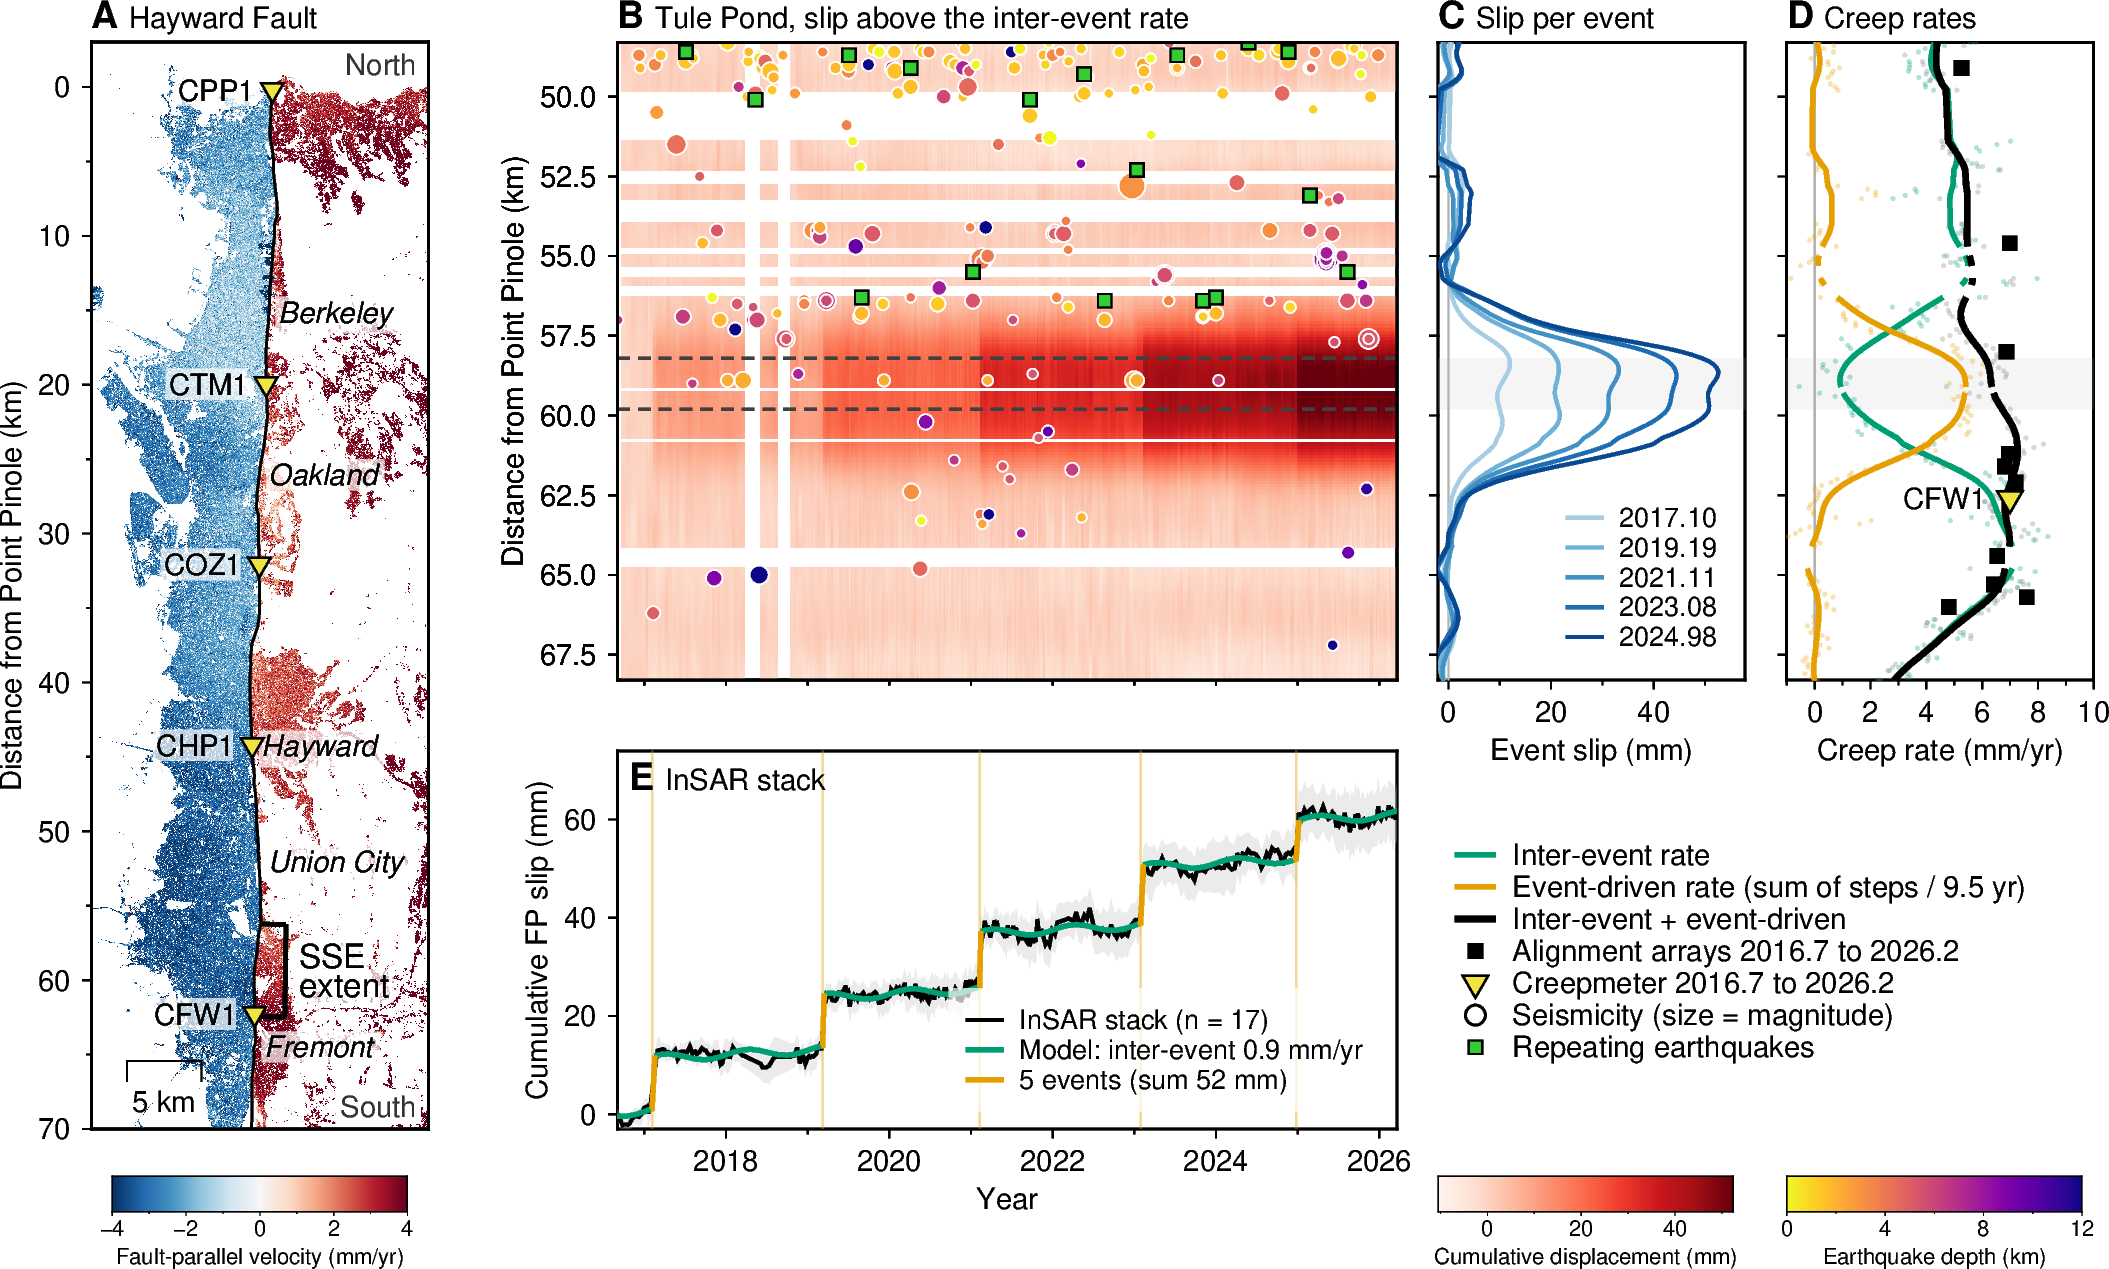

In [15]:
# [30]
# --- sizes in cm, double-column width, one font ---
teal, orange, cm_blue, gold = "#009E73", "#E69F00", "#0b3d91", "#F0E442"
hov_w, hov_h = 6.6, 5.4                          # hovmoller (6.6 cm keeps the page at the 18.3 cm Science full width)
stack_h = 3.2                                    # stack: shorter than the hovmoller, so B carries the figure
gap_stack = 0.6                                  # between B and E (B has no x annotation, E has its label inside)
map_w, map_h = 3.4, hov_h + gap_stack + stack_h  # map: as tall as B + gap + E, so the tops and bottoms line up
profile_w, rates_w, profile_h = 2.6, 2.6, hov_h  # profiles and rates panels: the same width
gap_map, gap_p, gap_r = 1.6, 0.35, 0.35          # B, C and D share one y axis, so the gaps are just the tick length
cb_w = 2.5                                       # every colour bar the same size and font (14p trick -> 7 pt)
cpt_dir = os.path.join(out_dir, "cpt")
os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "vel_vik.cpt"), "RdBu_r", -vel_lim, vel_lim)
cpt_hov = utils.write_cpt(os.path.join(cpt_dir, "hov_reds.cpt"), "Reds", vmin, vmax)
cpt_dep = utils.write_cpt(os.path.join(cpt_dir, "depth_plasma_r.cpt"), "plasma_r", 0, 12)

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", FONT_TITLE="9p,Helvetica-Bold",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: GMT oblique Mercator, fault up the page, north at the top; everything in lon/lat
region_map = f"{lon_ll}/{lat_ll}/{lon_ur}/{lat_ur}+r"
_, map_h_gmt = gmt_map_size(region_map, f"Oa{lon_c}/{lat_c}/{strike_map - 90}/{map_w}c")
map_w = map_w * map_h / map_h_gmt                                 # width that makes the map exactly map_h tall (true scale)
proj_map = f"Oa{lon_c}/{lat_c}/{strike_map - 90}/{map_w:.3f}c"
print(f"map panel {map_w:.2f} x {map_h:.2f} cm at true scale")
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
fig.grdimage(grid=grid_ll, cmap=cpt_vel, nan_transparent=True, interpolation="c")   # -nc: bicubic when GMT resamples the grid
                                                                                     # to the page (display only, the grid is the data)
fig.plot(x=x_fault["ft_lon"].values, y=x_fault["ft_lat"].values, pen="0.6p,black")
for code, la, lo, name in creepmeters:                                                                       # labels on the west (blue) side;
    utils.text_backed(fig, x=lo, y=la, text=code, justify="RM", offset="-0.15c/0c", font="7p,Helvetica,black")   # the triangles go on top, below
# the bracket spans the Tule Pond creep LENGTH (len_lo-len_hi, the 6 km of fault hosting the events, the number
# the paper quotes; section_lengths.csv), not the narrower stacked band, which stays as the dashed lines in B.
# East side of the fault so it stays clear of the creepmeter labels; labelled "SSE extent" (Dani 2026-09-29: it is the
# length that slips in the events, not the width of B), creepmeter style one size up
bracket_lon, bracket_lat = uv_to_lonlat([len_lo, len_hi], [2.0, 2.0])
fig.plot(x=bracket_lon, y=bracket_lat, pen="1.1p,black")
for u_ in (len_lo, len_hi):
    tick_lon, tick_lat = uv_to_lonlat([u_, u_], [0.4, 2.0])
    fig.plot(x=tick_lon, y=tick_lat, pen="1.1p,black")                                                      # ticks reach almost to the trace
# two rows in one call (GMT has no newline outside paragraph mode), boxed like the creepmeters, one size up
u_mid = 0.5 * (len_lo + len_hi)
label_lon, label_lat = uv_to_lonlat([u_mid - 1.0, u_mid + 1.0], [2.9, 2.9])       # left edge 0.9 km east of the bracket, never on it
utils.text_backed(fig, x=label_lon, y=label_lat, text=["SSE", "extent"], justify="LM", font="8p,Helvetica,black")
# the cities along the fault (Dani 2026-10-01), east side opposite the creepmeter labels. Each label sits within
# the city's stretch of the fault, not at its downtown (Oakland's downtown is on the bay flats and lines up with
# CTM1, the north end of the city's stretch). Labels only, nothing is measured from them:
#   Berkeley, Union City: the city centre's along-strike position
#   Oakland: midway between CTM1 (Temescal) and COZ1 (Oakland Zoo), both in Oakland
#   Hayward: at CHP1 (Palisade Street, Hayward)
#   Fremont: its centre (Central Park) sits beside the SSE bracket, so just south of the bracket, still in the city
# San Leandro is left off: the text does not mention it.
city_u = {"Berkeley": float(to_uv([-122.2727], [37.8716])[0][0]),
          "Oakland": 0.5 * (u_creepmeter["CTM1"] + u_creepmeter["COZ1"]),
          "Hayward": u_creepmeter["CHP1"],
          "Union City": float(to_uv([-122.0439], [37.5934])[0][0]),
          "Fremont": max(float(to_uv([-121.9886], [37.5485])[0][0]), len_hi + 2.0)}
for city, u_city in city_u.items():
    assert -3.0 < u_city < map_u_max, f"{city} (u {u_city:.1f} km) falls off the map"
    j = int(np.argmin(np.abs(trace_u_km - u_city)))
    city_lon, city_lat = uv_to_lonlat([u_city], [trace_v_km[j] + 0.6])
    utils.text_backed(fig, x=city_lon[0], y=city_lat[0], text=city, justify="LM", font="7p,Helvetica-Oblique,black")
print("city labels at km:", {c: round(u, 1) for c, u in city_u.items()})
for code, la, lo, name in creepmeters:                                                                       # the creepmeter symbol of D, on top of
    fig.plot(x=[lo], y=[la], style="i0.22c", fill=gold, pen="0.5p,black")                                    # every label (Dani 2026-10-01)
fig.text(position="TR", text="North", offset="-0.1c/-0.1c", font="7p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="BR", text="South", offset="-0.1c/0.1c", font="7p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="TL", text="@%Helvetica-Bold%A@%% @:7p:Hayward Fault@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w5k+o0.3c/0.4c")       # frame on top, scale bar
# distance from Point Pinole down the left edge (Dani 2026-10-01): the map's vertical IS the strike frame u (true
# scale, -3 km at the top to map_u_max at the bottom), so a linear axis over the same box reads u directly. Checked:
# GMT's own page y of the creepmeters must match the linear axis to 0.02 cm.
with pygmt.clib.Session() as lib, pygmt.helpers.GMTTempFile() as cm_xy:
    with pygmt.helpers.GMTTempFile() as cm_ll:
        np.savetxt(cm_ll.name, [[lo, la] for code, la, lo, name in creepmeters])
        lib.call_module("mapproject", f"{cm_ll.name} -R{region_map} -J{proj_map} ->{cm_xy.name}")
    cm_page_y = np.loadtxt(cm_xy.name, ndmin=2)[:, 1]
cm_axis_y = [map_h * (map_u_max - u_creepmeter[code]) / (map_u_max + 3.0) for code, la, lo, name in creepmeters]
assert np.max(np.abs(cm_page_y - cm_axis_y)) < 0.02, f"distance axis off the map by {np.max(np.abs(cm_page_y - cm_axis_y)):.3f} cm"
fig.basemap(region=[0, 1, -3.0, map_u_max], projection=f"X{map_w:.3f}c/-{map_h}c", frame=["W", "ya10f5+lDistance from Point Pinole (km)"])
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):     # GMT scales colour-bar text down with the bar thickness (-> ~6.5p)
    fig.colorbar(cmap=cpt_vel, position=f"x{0.5 * (map_w - cb_w)}c/-0.4c+w{cb_w}c/0.3c+h+jTL", frame="xa2f1+lFault-parallel velocity (mm/yr)")

# B) hovmoller, top of the middle column
fig.shift_origin(xshift=f"{map_w + gap_map}c", yshift=f"{map_h - hov_h}c")
region_hov = [t0, t1, w_lo, w_hi]
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])
fig.grdimage(grid=grid_hov, cmap=cpt_hov, nan_transparent=True)
fig.plot(x=seis_window.YYYY.values, y=seis_window.km.values, style="c", size=0.09 + 0.05 * np.clip(seis_window.Mag.values, 0, 5),
         fill=seis_window.Depth.values, cmap=cpt_dep, pen="0.3p,white")
fig.plot(x=cre_window.YYYY.values, y=cre_window.km.values, style="s0.16c", fill="limegreen", pen="0.4p,black")
for y_ in (band_lo, band_hi):
    fig.plot(x=[t0, t1], y=[y_, y_], pen="0.7p,gray25,3_2")
fig.text(x=t0, y=w_lo, text="@%Helvetica-Bold%B@%% @:7p:Tule Pond, slip above the inter-event rate@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])   # frame on top: a clean edge

# E) the stack, bottom of the middle column, bottom aligned with the map
fig.shift_origin(yshift=f"-{stack_h + gap_stack}c")
ok_stack = np.isfinite(band_main_stack["mean"])
region_stack = [t0, t1, -3, float(np.nanmax(band_main_stack["mean"] + band_main_stack["std"])) * 1.08]
fig.basemap(region=region_stack, projection=f"X{hov_w}c/{stack_h}c", frame=["WStr", "xa2f1+lYear", "ya20+lCumulative FP slip (mm)"])
envelope_x = np.r_[dates[ok_stack], dates[ok_stack][::-1]]
envelope_y = np.r_[(band_main_stack["mean"] + band_main_stack["std"])[ok_stack], (band_main_stack["mean"] - band_main_stack["std"])[ok_stack][::-1]]
fig.plot(x=envelope_x, y=envelope_y, fill="gray@70", close=True)
for onset in onsets_tulepond:
    fig.plot(x=[onset, onset], y=[region_stack[2], region_stack[3]], pen="0.5p," + orange + "@60")
fig.plot(x=dates[ok_stack], y=band_main_stack["mean"][ok_stack], pen="0.9p,black", label=f"InSAR stack (n = {band_main_stack['n']})")
fig.plot(x=dates, y=np.where(is_event_epoch, np.nan, model_full), pen="1.2p," + teal, label=f"Model: inter-event {band_main_stack['secular']:.1f} mm/yr")
fig.plot(x=dates, y=np.where(event_epochs_wide, model_full, np.nan), pen="1.2p," + orange, label=f"5 events (sum {np.sum(band_main_stack['steps']):.0f} mm)")
fig.text(position="TL", text="@%Helvetica-Bold%E@%% @:7p:InSAR stack@::", font="9p,Helvetica", offset="0.1c/-0.1c")
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.15c/0.15c", box="+gwhite@30")

# C) cumulative slip per event, right of the hovmoller
fig.shift_origin(xshift=f"{hov_w + gap_p}c", yshift=f"{stack_h + gap_stack}c")
xmax_profile = float(np.nanmax(cum_prof)) * 1.1
fig.basemap(region=[-2, xmax_profile, w_lo, w_hi], projection=f"X{profile_w}c/-{profile_h}c", frame=["wStr", "xa20f10+lEvent slip (mm)", "ya2.5"])
fig.plot(x=[-2, xmax_profile, xmax_profile, -2], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
blues = plt.get_cmap("Blues")
for i, onset in enumerate(onsets_tulepond):
    colour = "/".join(str(int(255 * v)) for v in blues(0.35 + 0.55 * i / 4)[:3])
    fig.plot(x=cum_prof[i], y=km_window, pen=f"0.9p,{colour}", label=f"{onset:.2f}")
fig.text(x=-2, y=w_lo, text="@%Helvetica-Bold%C@%% @:7p:Slip per event@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.1c/0.1c", box=False)

# D) creep rates: its y axis is shared with B, so no annotation
fig.shift_origin(xshift=f"{profile_w + gap_r}c")
in_window_budget = (slip_budget.km >= w_lo) & (slip_budget.km <= w_hi)
fig.basemap(region=[-1, 10, w_lo, w_hi], projection=f"X{rates_w}c/-{profile_h}c", frame=["wStr", "xa2f1+lCreep rate (mm/yr)", "ya2.5"])
fig.plot(x=[-1, 10, 10, -1], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
fig.plot(x=slip_budget.secular[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill=teal + "@70")
fig.plot(x=slip_budget.event_rate[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill=orange + "@70")
fig.plot(x=slip_budget.total[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill="gray50@70")
fig.plot(x=slip_budget.secular_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.2p," + teal, label="Inter-event rate")
fig.plot(x=slip_budget.event_rate_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.2p," + orange,
         label=f"Event-driven rate (sum of steps / {span:.1f} yr)")
fig.plot(x=slip_budget.total_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.5p,black", label="Inter-event + event-driven")
arrays_window = aa_rates[(aa_rates.km >= w_lo) & (aa_rates.km <= w_hi)]
arrays_refit = arrays_window[arrays_window.rate_window.notna()]
fig.plot(x=arrays_refit.rate_window.values, y=arrays_refit.km.values, style="s0.18c", fill="black", label=f"Alignment arrays {t0:.1f} to {t1:.1f}")
for code, (km_cm, rate_cm) in cm_rates.items():
    if w_lo <= km_cm <= w_hi:
        fig.plot(x=[rate_cm], y=[km_cm], style="i0.25c", fill=gold, pen="0.5p,black", label=f"Creepmeter {t0:.1f} to {t1:.1f}" if code == "CFW1" else None)
        fig.text(x=rate_cm, y=km_cm, text=code, justify="RM", offset="-0.2c/0c", font="7p", no_clip=True)
fig.text(x=-1, y=w_lo, text="@%Helvetica-Bold%D@%% @:7p:Creep rates@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
# legend entries for the symbols drawn in B: plotted off-region (clipped), so only the legend records them
fig.plot(x=[-50], y=[w_lo], style="c0.17c", pen="0.6p,black", label="Seismicity (size = magnitude)")
fig.plot(x=[-50], y=[w_lo], style="s0.16c", fill="limegreen", pen="0.4p,black", label="Repeating earthquakes")
# the legend of D in the free space under C and D
left_of_C = profile_w + gap_r                                          # from D's origin back to C's left edge
with pygmt.config(FONT_ANNOT_PRIMARY="7p"):                          # clear of the axis labels above it
    fig.legend(position=f"JBL+jTL+o-{left_of_C}c/1.2c+w{left_of_C + rates_w}c", box=False)
# the two colour bars of B, side by side, on the same line as the map's bar (0.4 cm below the map bottom)
cb_y = gap_stack + stack_h + 0.4
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):          # -> ~6.5 pt at this bar thickness, as A's
    fig.colorbar(cmap=cpt_hov, position=f"x-{left_of_C}c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa20f10+lCumulative displacement (mm)")
    fig.colorbar(cmap=cpt_dep, position=f"x0c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa4f2+lEarthquake depth (km)")

f_fig1 = os.path.join(fig_dir, f"fig1_tulepond_{params}_band{int(band_main * 100)}")
fig.savefig(f_fig1 + ".png", dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
fig.savefig(f_fig1 + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved Fig 1 to:", f_fig1 + ".png")
fig.show()

## [31] Figure: the slip budget along the whole fault (supplement)

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-09-30/figS_slip_budget_ap30-150m_coh0.7_mp5_sw200m.png


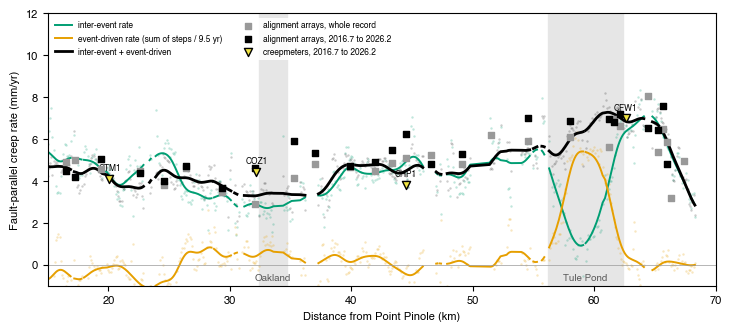

In [16]:
# [32]
fig, ax = plt.subplots(figsize=(7.2, 3.2), constrained_layout=True)
for name, (lo, hi) in (("Tule Pond", (len_lo, len_hi)), ("Oakland", (coz1_lo, coz1_hi))):
    ax.axvspan(lo, hi, color="0.9", zorder=0)
    ax.text(0.5 * (lo + hi), -0.75, name, ha="center", fontsize=7, color="0.35")
ax.scatter(slip_budget.km, slip_budget.secular, s=3, color=teal, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.event_rate, s=3, color=orange, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.total, s=3, color="k", alpha=0.2, lw=0)
ax.plot(slip_budget.km, slip_budget.secular_smooth, color=teal, lw=1.4, label="inter-event rate")
ax.plot(slip_budget.km, slip_budget.event_rate_smooth, color=orange, lw=1.4, label=f"event-driven rate (sum of steps / {span:.1f} yr)")
ax.plot(slip_budget.km, slip_budget.total_smooth, color="k", lw=2.0, label="inter-event + event-driven")
ax.scatter(aa_rates.km, aa_rates.rate_longterm, marker="s", s=14, color="0.6", zorder=4, label="alignment arrays, whole record")
ax.scatter(aa_rates.km, aa_rates.rate_window, marker="s", s=14, color="k", zorder=5, label=f"alignment arrays, {t0:.1f} to {t1:.1f}")
ax.scatter([km_cm for km_cm, rate_cm in cm_rates.values()], [rate_cm for km_cm, rate_cm in cm_rates.values()], marker="v", s=34,
           facecolor="#F0E442", edgecolor="k", zorder=6, label=f"creepmeters, {t0:.1f} to {t1:.1f}")
for code, (km_cm, rate_cm) in cm_rates.items():
    ax.annotate(code, (km_cm, rate_cm), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=6)
ax.set_xlim(*km_lim)
ax.set_ylim(-1, 12)
ax.axhline(0, color="0.6", lw=0.5)
ax.set_xlabel("Distance from Point Pinole (km)")
ax.set_ylabel("Fault-parallel creep rate (mm/yr)")
ax.legend(fontsize=6, loc="upper left", ncol=2)
f_budget = os.path.join(fig_dir, f"figS_slip_budget_{params}.png")
fig.savefig(f_budget, dpi=300)
fig.savefig(f_budget.replace(".png", ".pdf"))
print("Saved figure to:", f_budget)
plt.show()

## [33] REGISTER

In [17]:
# [34]
stats_lines = ["04 EVENT DETECTION",
               f"stream {params}; stack +/-{stack_half_km:g} km of the section centre; matched filter {win_n} epochs, "
               f"{k_sigma:g} sigma; joint model linear + annual + steps; {nboot} block bootstraps (~{block_years:g} yr blocks)", ""]
for key, sol in solutions.items():
    stats_lines.append(f"[{segments[key]['label']}] stack n = {sol['n']}, rate {sol['coef'][1]:.2f} mm/yr, "
                       f"annual {np.hypot(sol['coef'][2], sol['coef'][3]):.2f} mm, rms {np.sqrt(sol['rss'] / len(sol['dates'])):.2f} mm")
    for f in sol["fits"]:
        stats_lines.append(f"   onset {f['onset_yr']:.4f} [{f['onset_lo']:.4f}, {f['onset_hi']:.4f}] amp {f['amplitude_mm']:.2f} "
                           f"[{f['amp_lo']:.2f}, {f['amp_hi']:.2f}] mm")
stats_lines += ["", "event-driven fraction (crossings within 2 km of the section centre):"]
for key, stats in frac_stats.items():
    stats_lines.append(f"   {segments[key]['label']}: n {stats['n']}, summed slip median {stats['sum_median']:.1f} mm, "
                       f"fraction median {stats['median']:.0f}%, 5-95% {stats['p5']:.0f} to {stats['p95']:.0f}%")
stats_lines += ["", f"window {w_lo:.1f} to {w_hi:.1f} km (re-centred on the cumulative-slip peak at {peak_km:.1f} km); "
                f"median inter-event rate in the window {inter_event_rate_median:.2f} mm/yr",
                f"cumulative event slip peak {peak_cum:.1f} mm; flank threshold {length_threshold:.2f} mm (median {flank_median:.2f} + 3 x {flank_sigma:.2f})",
                f"length hosting the events: {len_lo:.1f} to {len_hi:.1f} km ({len_hi - len_lo:.1f} km, {len_n} crossings); "
                f"10%: {lengths['10pct'][1] - lengths['10pct'][0]:.1f} km; 20%: {lengths['20pct'][1] - lengths['20pct'][0]:.1f} km",
                f"fraction peak {peak_frac:.1f}%"]
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    stats_lines += [f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km ({hi_km - lo_km:.1f} km, {n_band} crossings); "
                    f"secular {result['secular']:.2f} mm/yr, annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm",
                    "   steps: " + ", ".join(f"{onset:.3f} {step:.2f} [{ci_lo:.2f}, {ci_hi:.2f}]"
                                             for onset, step, ci_lo, ci_hi in zip(onsets_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]))
                    + f"; sum {np.sum(result['steps']):.1f}, mean {np.mean(result['steps']):.1f} mm"]
stats_lines += ["", "slip budget (mm/yr; arrays within 1 km of the block, refit over the InSAR window / whole record):"]
for name, block in budget.items():
    stats_lines.append(f"   {block['name']}: {block['lo']:.1f} to {block['hi']:.1f} km n {block['n']}: secular {block['secular']:.2f}, "
                       f"event {block['event_rate']:.2f}, total {block['total']:.2f} ({block['frac_pct']:.0f}%), arrays window "
                       f"{block['aa_window_mean']:.2f} (n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']})")
stats_lines += ["", "recurrence intervals (yr): " + ", ".join(f"{x:.2f}" for x in intervals) +
                f"; mean {intervals.mean():.2f}, sd {intervals.std(ddof=1) * 365.25:.0f} d, CoV {intervals.std(ddof=1) / intervals.mean():.2f}",
                f"seismicity (GrowClust) within {seis_max_dist_km:g} km, window {w_lo:.0f}-{w_hi:.0f} km: {n_seis_win} earthquakes, "
                f"{n_cre_win} repeaters, {n_cre_band} repeaters in the {100 * band_main:.0f}% band",
                f"hovmoller colour scale {vmin:.0f} to {vmax:.0f} mm"]
sidecar = REG.sidecar("04_events", stats_lines)

REG.register("04_n_events", len(tulepond_events), "count", 0, where="P3, abstract", cell="detect", sidecar=sidecar)
REG.register("04_detect_sigma_mm", float(tulepond_events.detect_sigma_mm[0]), "mm", 3, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_threshold_mm", k_sigma * float(tulepond_events.detect_sigma_mm[0]), "mm", 2, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_stack_n_crossings", solutions["TULEPOND"]["n"], "count", 0, where="M5", cell="detect", sidecar=sidecar)
labels = [f"{int(onset)}" for onset in onsets_tulepond]
for label, (_, event) in zip(labels, tulepond_events.iterrows()):
    REG.register(f"04_onset_{label}", event.onset_yr, "decyear", 3, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_lo_{label}", event.onset_lo, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_hi_{label}", event.onset_hi, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_window_days_{label}", event.onset_window_days, "d", 0, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_stack_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5", cell="joint-fit", sidecar=sidecar)
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    tag = f"band{int(band_frac * 100)}"
    REG.register(f"04_{tag}_lo_km", lo_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_hi_km", hi_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_width_km", hi_km - lo_km, "km", 1, where="P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_n_crossings", n_band, "count", 0, where="Fig1 caption", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_inter_event_mm_yr", result["secular"], "mm/yr", 2, where="P4, Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_annual_mm", result["annual"], "mm", 2, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_sum_mm", float(np.sum(result["steps"])), "mm", 1, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_mean_mm", float(np.mean(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_min_mm", float(np.min(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_max_mm", float(np.max(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    for label, step, ci_lo, ci_hi in zip(labels, result["steps"], result["ci_lo"], result["ci_hi"]):
        REG.register(f"04_{tag}_step_{label}_mm", step, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_lo", ci_lo, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_hi", ci_hi, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
REG.register("04_creep_length_km", len_hi - len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_lo_km", len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_hi_km", len_hi, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_n_crossings", len_n, "count", 0, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_threshold_mm", length_threshold, "mm", 2, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_10pct_km", lengths["10pct"][1] - lengths["10pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_20pct_km", lengths["20pct"][1] - lengths["20pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_fraction_peak_pct", peak_frac, "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_median_pct", frac_stats["TULEPOND"]["median"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p5_pct", frac_stats["TULEPOND"]["p5"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p95_pct", frac_stats["TULEPOND"]["p95"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_event_slip_sum_median_mm", frac_stats["TULEPOND"]["sum_median"], "mm", 1, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_hovmoller_bg_rate_mm_yr", inter_event_rate_median, "mm/yr", 1, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
REG.register("04_hovmoller_vmax_mm", vmax, "mm", 0, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
for name, block in budget.items():
    for quantity in ("secular", "event_rate", "total"):
        REG.register(f"04_budget_{name}_{quantity.replace('secular', 'inter_event')}_mm_yr", block[quantity], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_event_pct", block["frac_pct"], "pct", 0, where="P4", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_window_mm_yr", block["aa_window_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_longterm_mm_yr", block["aa_longterm_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_n", block["aa_n"], "count", 0, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register("04_record_span_yr", span, "yr", 2, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register_many("04_interval_yr", list(intervals), "yr", 2, where="P9", cell="intervals",
                  labels=[f"{int(a)}_{int(b)}" for a, b in zip(onsets_tulepond[:-1], onsets_tulepond[1:])], sidecar=sidecar)
REG.register("04_interval_mean_yr", intervals.mean(), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_interval_sd_d", intervals.std(ddof=1) * 365.25, "d", 0, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_interval_cov", intervals.std(ddof=1) / intervals.mean(), "1", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_n_seis_window", n_seis_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_window", n_cre_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_band", n_cre_band, "count", 0, where="P3", cell="catalogues", sidecar=sidecar)
for label, event in zip(["2019", "2022", "2024"], creep_events[creep_events.segment == "COZ1"].itertuples()):
    REG.register(f"04_control_coz1_onset_{label}", event.onset_yr, "decyear", 3, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_creepmeter_{label}_mm", event.creepmeter_step_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/04_event_detection/04_events_stats.txt
  registered 04_n_events = 5 count  -> P3, abstract


  registered 04_detect_sigma_mm = 0.763 mm  -> M5
  registered 04_threshold_mm = 2.29 mm  -> M5
  registered 04_stack_n_crossings = 45 count  -> M5


  registered 04_onset_2017 = 2017.099 decyear  -> P3
  registered 04_onset_lo_2017 = 2017.0822 decyear  -> P3


  registered 04_onset_hi_2017 = 2017.0986 decyear  -> P3
  registered 04_onset_window_days_2017 = 6 d  -> P3
  registered 04_stack_amp_2017_mm = 9.17 mm  -> M5


  registered 04_onset_2019 = 2019.186 decyear  -> P3
  registered 04_onset_lo_2019 = 2019.1699 decyear  -> P3


  registered 04_onset_hi_2019 = 2019.1863 decyear  -> P3
  registered 04_onset_window_days_2019 = 6 d  -> P3
  registered 04_stack_amp_2019_mm = 9.17 mm  -> M5


... (51 outputs left out)

  registered 04_control_coz1_amp_2019_mm = 2.30 mm  -> M5 (control)
  registered 04_control_coz1_creepmeter_2019_mm = 3.94 mm  -> M5 (control)
  registered 04_control_coz1_onset_2022 = 2022.126 decyear  -> M5 (control)


  registered 04_control_coz1_amp_2022_mm = 4.67 mm  -> M5 (control)
  registered 04_control_coz1_creepmeter_2022_mm = 7.31 mm  -> M5 (control)


Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'